# CREMA-D: Baseline + OPM, OGM-GE, OPM+OGM-GE, AGM, PMR

**Portable version for a new Colab account.** The first setup cell clones `https://github.com/Vaishnavi23457/DL_project.git` when needed and fetches the baseline checkpoint and metadata from GitHub paths. It also attempts to download the raw CREMA-D dataset from the mirror referenced by the original project notebook.

Pipeline: repository/checkpoint validation → metadata path repair → audio/video preprocessing → model/checkpoint compatibility checks → baseline evaluation → OPM, OGM-GE, OPM+OGM-GE, AGM, PMR experiment routines → results CSV and plots.

**Important:** raw CREMA-D audio/video files are not in GitHub. The notebook attempts the original dataset mirror; if that mirror is unavailable, place the dataset in `/content/CREMA-D/AudioWAV` and `/content/CREMA-D/VideoFlash`. Also, algorithm routines are adaptations of the method ideas and need paper-specific validation before reporting results.

In [1]:
# 0. Portable setup for a NEW Colab account/runtime
%pip install -q librosa soundfile opencv-python-headless scikit-learn pandas matplotlib nbformat tqdm gdown

import os, json, math, random, copy, inspect, ast, subprocess, shutil, zipfile
from pathlib import Path
from io import StringIO
import requests, cv2, librosa, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import nbformat

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

# Source of truth: GitHub repository. This cell works in a fresh Colab account.
GITHUB_REPO="https://github.com/Vaishnavi23457/DL_project.git"
REPO=Path("/content/DL_project")
if not REPO.exists():
    subprocess.run(["git","clone",GITHUB_REPO,str(REPO)],check=True)
else:
    print("Using existing clone:", REPO)

PROJECT=REPO/"modality_bias"
RESULTS=PROJECT/"results"
CKPTS=PROJECT/"checkpoints"
ORIG_NB=PROJECT/"notebooks/01-setup-and-model-crema-d-mbs.ipynb"
BASE_CKPT=CKPTS/"crema_d_baseline_best.pth"
META_CSV=RESULTS/"crema_d_metadata.csv"

# Ensure checkpoint and metadata are available from the public GitHub raw URLs
# if a local clone is incomplete.
BASE_CKPT_URL="https://raw.githubusercontent.com/Vaishnavi23457/DL_project/main/modality_bias/checkpoints/crema_d_baseline_best.pth"
META_URL="https://raw.githubusercontent.com/Vaishnavi23457/DL_project/main/modality_bias/results/crema_d_metadata.csv"
RESULTS.mkdir(parents=True,exist_ok=True)
CKPTS.mkdir(parents=True,exist_ok=True)
if not BASE_CKPT.exists():
    rr=requests.get(BASE_CKPT_URL,timeout=180); rr.raise_for_status()
    BASE_CKPT.write_bytes(rr.content)
if not META_CSV.exists():
    rr=requests.get(META_URL,timeout=60); rr.raise_for_status()
    META_CSV.write_bytes(rr.content)

# CREMA-D raw recordings are NOT stored in the GitHub repository.
# Reuse the public mirror referenced by the project's original notebook.
RAW=Path("/content/CREMA-D")
AUDIO_DIR=RAW/"AudioWAV"
VIDEO_DIR=RAW/"VideoFlash"
ARCHIVE=Path("/content/crema-d.zip")

if not (AUDIO_DIR.exists() and VIDEO_DIR.exists()):
    print("CREMA-D raw files not found in this new runtime.")
    print("Attempting the dataset mirror referenced in the original project notebook...")
    if not ARCHIVE.exists():
        try:
            subprocess.run([
                "gdown","--id","1MPiFfSiEanCNu5HSon5Y2dGHsnpsUtRm",
                "-O",str(ARCHIVE)
            ],check=True)
        except Exception as e:
            raise RuntimeError(
                "Dataset download failed. The checkpoint and metadata are fetched from GitHub, "
                "but CREMA-D audio/video files are not committed to the repository. "
                "Download CREMA-D into /content/CREMA-D with AudioWAV/ and VideoFlash/ folders, "
                "then rerun this cell. Original download error: "+repr(e)
            )
    if not zipfile.is_zipfile(ARCHIVE):
        raise RuntimeError(f"Dataset archive is not a valid ZIP: {ARCHIVE}")
    with zipfile.ZipFile(ARCHIVE) as z:
        z.extractall("/content")
    # Some archives extract a nested root directory; find the actual folders.
    audio_matches=list(Path("/content").glob("**/AudioWAV"))
    video_matches=list(Path("/content").glob("**/VideoFlash"))
    pairs=[(a,v) for a in audio_matches for v in video_matches if a.parent==v.parent]
    if pairs:
        AUDIO_DIR,VIDEO_DIR=pairs[0]
        RAW=AUDIO_DIR.parent

assert BASE_CKPT.exists(), f"Baseline checkpoint unavailable: {BASE_CKPT}"
assert META_CSV.exists(), f"Metadata unavailable: {META_CSV}"
assert AUDIO_DIR.exists() and VIDEO_DIR.exists(), (
    f"Raw dataset folders missing. Expected AudioWAV and VideoFlash. "
    f"Found AUDIO_DIR={AUDIO_DIR}, VIDEO_DIR={VIDEO_DIR}"
)
print("Repository:",REPO)
print("Baseline checkpoint:",BASE_CKPT,f"({BASE_CKPT.stat().st_size/1e6:.1f} MB)")
print("Metadata:",META_CSV)
print("Audio directory:",AUDIO_DIR)
print("Video directory:",VIDEO_DIR)

Device: cuda | GPU: Tesla T4
CREMA-D raw files not found in this new runtime.
Attempting the dataset mirror referenced in the original project notebook...
Repository: /content/DL_project
Baseline checkpoint: /content/DL_project/modality_bias/checkpoints/crema_d_baseline_best.pth (46.4 MB)
Metadata: /content/DL_project/modality_bias/results/crema_d_metadata.csv
Audio directory: /content/datasets/CREMA-D/AudioWAV
Video directory: /content/datasets/CREMA-D/VideoFlash


## 1. Metadata and path repair

Uses the metadata CSV fetched from the GitHub repository and rebuilds stale Kaggle audio/video paths from each sample ID. The committed split is preserved.

In [2]:
meta=pd.read_csv(META_CSV)
required={"id","audio","video","speaker","label","emotion","split"}
assert required.issubset(meta.columns), f"Missing columns: {required-set(meta.columns)}"
# The committed CSV has old environment-specific paths. Rebuild them using IDs
# while preserving the committed labels and train/validation/test split.
meta["audio"]=meta["id"].astype(str).map(lambda x:str(AUDIO_DIR/f"{x}.wav"))
meta["video"]=meta["id"].astype(str).map(lambda x:str(VIDEO_DIR/f"{x}.flv"))
meta["label"]=meta["label"].astype(int)
print("Metadata shape:",meta.shape,"| split counts:",meta["split"].value_counts().to_dict())
missing=meta[~meta.audio.map(lambda p:Path(p).is_file()) | ~meta.video.map(lambda p:Path(p).is_file())]
print("Missing paired files:",len(missing))
if len(missing):
    display(missing[["id","audio","video"]].head(10))
    raise FileNotFoundError(
        f"{len(missing)} rows have missing audio/video. Check the extracted CREMA-D folder structure."
    )

Metadata shape: (7437, 7) | split counts: {'train': 5226, 'val': 1146, 'test': 1065}
Missing paired files: 0


## 2. Audio preprocessing and video frame cache

First run caches 8 frames per clip at 224×224. The cache is local to this Colab runtime.

In [4]:

from pathlib import Path
import torch

# Preprocessing configuration
AUDIO_SR = 16000
AUDIO_SECONDS = 4
N_MELS = 64
NUM_FRAMES = 8
IMAGE_SIZE = 224
BATCH_SIZE = 16 if torch.cuda.is_available() else 4

# Define cache directory
CACHE = Path("/content/cremad_frame_cache")
CACHE.mkdir(parents=True, exist_ok=True)

print("Cache directory:", CACHE)
print("GPU available:", torch.cuda.is_available())
print("Batch size:", BATCH_SIZE)


Cache directory: /content/cremad_frame_cache
GPU available: True
Batch size: 16


In [5]:

AUDIO_SR=16000; AUDIO_SECONDS=4; N_MELS=64; NUM_FRAMES=8; IMAGE_SIZE=224
BATCH_SIZE=16 if torch.cuda.is_available() else 4
CACHE.mkdir(parents=True,exist_ok=True)

def load_audio(path):
    y,_=librosa.load(str(path),sr=AUDIO_SR,mono=True)
    L=AUDIO_SR*AUDIO_SECONDS
    y=np.pad(y,(0,max(0,L-len(y))))[:L]
    mel=librosa.feature.melspectrogram(y=y,sr=AUDIO_SR,n_mels=N_MELS,n_fft=1024,hop_length=256)
    mel=librosa.power_to_db(mel,ref=np.max).astype(np.float32)
    return (mel-mel.mean())/(mel.std()+1e-6)

def cache_frames(video_path,out_path):
    cap=cv2.VideoCapture(str(video_path))
    if not cap.isOpened(): raise RuntimeError(f"Cannot open {video_path}")
    total=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total<=0: cap.release(); raise RuntimeError(f"Invalid video {video_path}")
    frames=[]
    for i in np.linspace(0,total-1,NUM_FRAMES).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES,int(i)); ok,frame=cap.read()
        if ok:
            frame=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
            frames.append(cv2.resize(frame,(IMAGE_SIZE,IMAGE_SIZE)))
    cap.release()
    if not frames: raise RuntimeError(f"No frames decoded: {video_path}")
    while len(frames)<NUM_FRAMES: frames.append(frames[-1].copy())
    arr=np.transpose(np.stack(frames[:NUM_FRAMES]).astype(np.uint8),(0,3,1,2))
    np.save(out_path,arr)

for row in tqdm(meta.itertuples(index=False),total=len(meta),desc="Caching frames"):
    p=CACHE/f"{row.id}.npy"
    if not p.exists(): cache_frames(row.video,p)
print("Cached arrays:",len(list(CACHE.glob("*.npy"))))
print("Audio feature shape:",load_audio(meta.iloc[0].audio).shape)


Caching frames:   0%|          | 0/7437 [00:00<?, ?it/s]

Cached arrays: 7437
Audio feature shape: (64, 251)


## 3. Dataset and data loaders

In [6]:

class CREMADDataset(Dataset):
    def __init__(self,df):
        self.df=df.reset_index(drop=True)
        self.norm=transforms.Normalize([.485,.456,.406],[.229,.224,.225])
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        a=torch.from_numpy(load_audio(r.audio)).unsqueeze(0).float()
        v=torch.from_numpy(np.load(CACHE/f"{r['id']}.npy")).float()/255.
        v=torch.stack([self.norm(x) for x in v])
        return {"audio":a,"visual":v,"label":torch.tensor(int(r.label),dtype=torch.long),"id":str(r["id"])}

train_ds=CREMADDataset(meta[meta.split=="train"])
val_ds=CREMADDataset(meta[meta.split=="val"])
test_ds=CREMADDataset(meta[meta.split=="test"])
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
print("Train/val/test:",len(train_ds),len(val_ds),len(test_ds))
b=next(iter(train_loader))
print({k:(tuple(v.shape) if torch.is_tensor(v) else len(v)) for k,v in b.items()})


Train/val/test: 5226 1146 1065
{'audio': (16, 1, 64, 251), 'visual': (16, 8, 3, 224, 224), 'label': (16,), 'id': 16}


## 4. Checkpoint inspection and recover original model class

The notebook scans the repository's original notebook for candidate model-class cells. It does not invent a replacement architecture. If strict loading fails, stop and fix compatibility before interpreting any results.

In [7]:

orig=nbformat.read(str(ORIG_NB),as_version=4) if ORIG_NB.exists() else None
if orig is None:
    u="https://raw.githubusercontent.com/Vaishnavi23457/DL_project/main/modality_bias/notebooks/01-setup-and-model-crema-d-mbs.ipynb"
    rr=requests.get(u,timeout=60); rr.raise_for_status(); orig=nbformat.reads(rr.text,as_version=4)
code_cells=[(i,c.source) for i,c in enumerate(orig.cells) if c.cell_type=="code"]
candidates=[]
for i,src in code_cells:
    low=src.lower()
    if "class " in src and "nn.Module" in src and any(k in low for k in ["audio_encoder","visual_encoder","audio_head","fusion"]):
        candidates.append((i,src))
        print(f"Candidate model cell {i}:\n{src[:1600]}\n---")

obj=torch.load(BASE_CKPT,map_location="cpu",weights_only=False)
state=None
if isinstance(obj,dict):
    for k in ["model_state_dict","state_dict","model","net","weights"]:
        if k in obj and isinstance(obj[k],dict): state=obj[k]; print("State dict nested under",k); break
    if state is None and obj and all(torch.is_tensor(v) for v in obj.values()): state=obj
print("Checkpoint object:",type(obj))
print("Checkpoint keys:",list(obj.keys())[:30] if isinstance(obj,dict) else "not a dict")
print("State entries:",len(state) if state is not None else None)
if state is not None: print("\n".join(list(state.keys())[:60]))


Candidate model cell 13:
# ============================================================
# 8. BASELINE MODEL
# ============================================================
class AudioEncoder(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.fc = nn.Linear(128, out_dim)

    def forward(self, x):
        return self.fc(self.net(x).flatten(1))

class VisualEncoder(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()
        base = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.features = nn.Sequential(*list(base.children())[:-1])
        sel

In [13]:

import torchvision.models as models

NUM_CLASSES = 6
num_classes = NUM_CLASSES
N_CLASSES = NUM_CLASSES
n_classes = NUM_CLASSES

print("torchvision.models imported successfully")
print("Number of classes:", NUM_CLASSES)


torchvision.models imported successfully
Number of classes: 6


In [14]:

# Execute only likely model-class cells (not training cells).
for i,src in candidates:
    try:
        exec(compile(src,f"<original_cell_{i}>","exec"),globals())
        print("Executed model cell",i)
    except Exception as e:
        print("Candidate cell failed",i,repr(e))

classes=[]
for name,x in list(globals().items()):
    if inspect.isclass(x) and issubclass(x,nn.Module) and x is not nn.Module:
        if any(k in name.lower() for k in ["model","network","classifier","emotion"]): classes.append(name)
print("Model-like classes found:",classes)

# Try a simple original statement: model = SomeClass(...)
construction=None
for i,src in code_cells:
    try: tree=ast.parse(src)
    except SyntaxError: continue
    for node in tree.body:
        if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id=="model" for t in node.targets):
            if isinstance(node.value,ast.Call) and isinstance(node.value.func,ast.Name):
                if node.value.func.id in globals() and inspect.isclass(globals()[node.value.func.id]):
                    construction=ast.get_source_segment(src,node); break
    if construction: break
if "model" not in globals() and construction:
    print("Trying constructor:",construction)
    try: exec(construction,globals())
    except Exception as e: print("Constructor failed:",repr(e))

if "model" not in globals():
    raise RuntimeError("Could not recover model instance automatically. Use the printed candidate cells/checkpoint keys to resolve the original constructor; do not substitute a new architecture.")
model=model.to(DEVICE)
if state is None: raise RuntimeError("Checkpoint state dict could not be identified.")
model.load_state_dict(state,strict=True)
print("Strict checkpoint load successful:",type(model).__name__)
print("Required components:",{x:hasattr(model,x) for x in ["audio_encoder","visual_encoder","audio_head","visual_head"]})


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Parameters: 11,569,938
Executed model cell 13
Model-like classes found: []
Strict checkpoint load successful: MultimodalBaseline
Required components: {'audio_encoder': True, 'visual_encoder': True, 'audio_head': True, 'visual_head': True}


## 5. Baseline evaluation and architecture checks

In [15]:

def logits_of(x):
    if torch.is_tensor(x): return x
    if isinstance(x,dict):
        for k in ["logits","fusion_logits","pred"]:
            if k in x and torch.is_tensor(x[k]): return x[k]
    if isinstance(x,(tuple,list)):
        for z in x:
            if torch.is_tensor(z) and z.ndim==2: return z
    raise TypeError(f"Cannot identify logits in {type(x)}")

def move_batch(batch):
    return batch["audio"].to(DEVICE),batch["visual"].to(DEVICE),batch["label"].to(DEVICE)

def evaluate(model,loader,desc):
    model.eval(); ys=[]; ps=[]; losses=[]
    with torch.no_grad():
        for batch in tqdm(loader,desc=desc):
            a,v,y=move_batch(batch); z=logits_of(model(a,v))
            losses.append(nn.functional.cross_entropy(z,y).item())
            ys.extend(y.cpu().tolist()); ps.extend(z.argmax(1).cpu().tolist())
    return {"loss":float(np.mean(losses)),"accuracy":accuracy_score(ys,ps),
            "macro_f1":f1_score(ys,ps,average="macro"),"n_test":len(ys)}
assert all(hasattr(model,x) for x in ["audio_encoder","visual_encoder","audio_head","visual_head"]), "Model lacks modality-specific encoders/heads required by these methods."
batch=next(iter(test_loader))
with torch.no_grad():
    z=logits_of(model(batch["audio"].to(DEVICE),batch["visual"].to(DEVICE)))
assert z.shape[-1]==6, f"Expected 6 classes, got {tuple(z.shape)}"
baseline=evaluate(model,test_loader,"Baseline test")
print("Baseline:",baseline)


Baseline test:   0%|          | 0/67 [00:00<?, ?it/s]

Baseline: {'loss': 2.0708817706179263, 'accuracy': 0.6281690140845071, 'macro_f1': 0.6180973766947725, 'n_test': 1065}


## 6. Training methods

Methods implemented here:
- **OPM:** dynamically drops the stronger modality's encoder output during training.
- **OGM-GE:** scales gradients of the dominant modality and adds Gaussian gradient noise.
- **OPM+OGM-GE:** applies both.
- **AGM:** smooths confidence-derived modulation coefficients over training batches.
- **PMR:** adds a prototype-based auxiliary loss to modality features.

These are model-adapted implementations of the method concepts. Exact paper reproduction requires matching each paper's precise coefficient equations, losses, and hyperparameters.

In [16]:

EPOCHS=5  # Change to 15 for full runs after a one-epoch smoke test
LR=1e-4; WD=1e-4; OGM_ALPHA=.5; GE_NOISE=.01; OPM_MAX_DROP=.5; PMR_WEIGHT=.1
NUM_CLASSES=6
criterion=nn.CrossEntropyLoss()

def feat(x):
    if isinstance(x,dict):
        for k in ["features","embedding","pooler_output","last_hidden_state"]:
            if k in x and torch.is_tensor(x[k]): x=x[k]; break
    if isinstance(x,(tuple,list)): x=next(t for t in x if torch.is_tensor(t))
    if not torch.is_tensor(x): raise TypeError("Encoder output is not a tensor")
    return x.flatten(1) if x.ndim>2 else x

def branches(m,a,v):
    af=feat(m.audio_encoder(a)); vf=feat(m.visual_encoder(v))
    return af,vf,m.audio_head(af),m.visual_head(vf)

def coeffs(al,vl,y):
    with torch.no_grad():
        pa=al.softmax(1).gather(1,y[:,None]).mean().clamp_min(1e-6).item()
        pv=vl.softmax(1).gather(1,y[:,None]).mean().clamp_min(1e-6).item()
    ca=cv=1.
    if pa>pv: ca=float(np.clip(math.exp(OGM_ALPHA*(1-pa/pv)),0,1))
    elif pv>pa: cv=float(np.clip(math.exp(OGM_ALPHA*(1-pv/pa)),0,1))
    return pa,pv,ca,cv

def scale_grads(module,scale,noise=False):
    for p in module.parameters():
        if p.grad is not None:
            p.grad.mul_(scale)
            if noise and scale<1:
                p.grad.add_(torch.randn_like(p.grad)*GE_NOISE*p.grad.detach().std().clamp_min(1e-8))

def prototypes_loss(x,y):
    protos=[]
    for c in range(NUM_CLASSES):
        mask=y==c
        protos.append(x[mask].mean(0) if mask.any() else x.mean(0))
    protos=F.normalize(torch.stack(protos).detach(),dim=1)
    x=F.normalize(x,dim=1)
    return F.cross_entropy(x@protos.T/.1,y)

def train_epoch(m,loader,opt,method,epoch,agm):
    m.train(); losses=[]; ys=[]; ps=[]
    for batch in tqdm(loader,desc=f"{method} train {epoch}"):
        a,v,y=move_batch(batch); opt.zero_grad(set_to_none=True)
        # Confidence estimate before modulation.
        with torch.no_grad(): af0,vf0,al0,vl0=branches(m,a,v); pa,pv,ca,cv=coeffs(al0,vl0,y)
        handles=[]
        if method in ["OPM","OPM+OGM-GE"]:
            dominant="audio" if pa>pv else ("visual" if pv>pa else None)
            if dominant:
                pdrop=min(OPM_MAX_DROP,max(0.,1-min(pa,pv)/max(pa,pv)))
                if pdrop:
                    enc=m.audio_encoder if dominant=="audio" else m.visual_encoder
                    def hook(mod,inp,out,p=pdrop):
                        if torch.is_tensor(out):
                            shape=[out.shape[0]]+[1]*(out.ndim-1)
                            keep=(torch.rand(shape,device=out.device)>=p).to(out.dtype)
                            return out*keep
                        return out
                    handles.append(enc.register_forward_hook(hook))
        try:
            af,vf,al,vl=branches(m,a,v)
            fused=logits_of(m(a,v))
            loss=criterion(fused,y)
            if method=="PMR":
                loss=loss+PMR_WEIGHT*(prototypes_loss(af,y)+prototypes_loss(vf,y))
            loss.backward()
            if method in ["OGM-GE","OPM+OGM-GE"]:
                scale_grads(m.audio_encoder,ca,True); scale_grads(m.visual_encoder,cv,True)
            elif method=="AGM":
                agm["a"]=.9*agm["a"]+.1*ca; agm["v"]=.9*agm["v"]+.1*cv
                scale_grads(m.audio_encoder,agm["a"]); scale_grads(m.visual_encoder,agm["v"])
            opt.step()
            losses.append(loss.item()); ys.extend(y.cpu().tolist()); ps.extend(fused.detach().argmax(1).cpu().tolist())
        finally:
            for h in handles: h.remove()
    return {"train_loss":float(np.mean(losses)),"train_accuracy":accuracy_score(ys,ps),
            "train_macro_f1":f1_score(ys,ps,average="macro")}


In [17]:

METHODS=["OPM","OGM-GE","OPM+OGM-GE","AGM","PMR"]
# Start with ["OGM-GE"] and EPOCHS=1 to smoke-test the complete pipeline.
# Each method starts from the same baseline checkpoint; baseline file is never overwritten.
def run_method(method,epochs=EPOCHS):
    m=copy.deepcopy(model).to(DEVICE); m.load_state_dict(state,strict=True)
    opt=torch.optim.AdamW(m.parameters(),lr=LR,weight_decay=WD)
    agm={"a":1.,"v":1.}; best=-1.; best_state=None; hist=[]
    for ep in range(1,epochs+1):
        tr=train_epoch(m,train_loader,opt,method,ep,agm)
        va=evaluate(m,val_loader,f"{method} val {ep}")
        row={"method":method,"epoch":ep,**tr,**{f"val_{k}":v for k,v in va.items()}}
        hist.append(row); print(row)
        if va["macro_f1"]>best:
            best=va["macro_f1"]; best_state={k:v.detach().cpu().clone() for k,v in m.state_dict().items()}
    m.load_state_dict(best_state,strict=True)
    tag=method.lower().replace("+","_")
    cp=CKPTS/f"crema_d_{tag}_best.pth"
    torch.save({"method":method,"model_state_dict":m.state_dict(),"best_val_macro_f1":best,"seed":SEED},cp)
    pd.DataFrame(hist).to_csv(RESULTS/f"crema_d_{tag}_history.csv",index=False)
    te=evaluate(m,test_loader,f"{method} test")
    return {"method":method,"best_val_macro_f1":best,"test_loss":te["loss"],
            "test_accuracy":te["accuracy"],"test_macro_f1":te["macro_f1"],
            "n_test":te["n_test"],"checkpoint":str(cp)}

results=[{"method":"Baseline_checkpoint","best_val_macro_f1":np.nan,
          "test_loss":baseline["loss"],"test_accuracy":baseline["accuracy"],
          "test_macro_f1":baseline["macro_f1"],"n_test":baseline["n_test"],
          "checkpoint":str(BASE_CKPT)}]
for method in METHODS:
    results.append(run_method(method))
    pd.DataFrame(results).to_csv(RESULTS/"crema_d_method_comparison.csv",index=False)
comparison=pd.DataFrame(results)
display(comparison.sort_values("test_macro_f1",ascending=False))


OPM train 1:   0%|          | 0/327 [00:00<?, ?it/s]

OPM val 1:   0%|          | 0/72 [00:00<?, ?it/s]

{'method': 'OPM', 'epoch': 1, 'train_loss': 0.6001421755652544, 'train_accuracy': 0.7690394182931496, 'train_macro_f1': 0.7684599589887985, 'val_loss': 1.581005448061559, 'val_accuracy': 0.6099476439790575, 'val_macro_f1': 0.6079083322581009, 'val_n_test': 1146}


OPM train 2:   0%|          | 0/327 [00:00<?, ?it/s]

OPM val 2:   0%|          | 0/72 [00:00<?, ?it/s]

...

PMR train 5:   0%|          | 0/327 [00:00<?, ?it/s]

PMR val 5:   0%|          | 0/72 [00:00<?, ?it/s]

{'method': 'PMR', 'epoch': 5, 'train_loss': 0.2492118031014361, 'train_accuracy': 0.9584768465365481, 'train_macro_f1': 0.9580446043359941, 'val_loss': 1.7358416482392285, 'val_accuracy': 0.6518324607329843, 'val_macro_f1': 0.6375901803727219, 'val_n_test': 1146}


PMR test:   0%|          | 0/67 [00:00<?, ?it/s]

,method,best_val_macro_f1,test_loss,test_accuracy,test_macro_f1,n_test,checkpoint
1,OPM,0.673605,1.249858,0.672300,0.671995,1065,/content/DL_project/modality_bias/checkpoints/...
2,OGM-GE,0.651948,1.667015,0.637559,0.636086,1065,/content/DL_project/modality_bias/checkpoints/...
5,PMR,0.660903,1.690941,0.637559,0.632595,1065,/content/DL_project/modality_bias/checkpoints/...
0,Baseline_checkpoint,NaN,2.070882,0.628169,0.618097,1065,/content/DL_project/modality_bias/checkpoints/...
3,OPM+OGM-GE,0.636847,1.527088,0.620657,0.615176,1065,/content/DL_project/modality_bias/checkpoints/...
4,AGM,0.662307,1.620180,0.626291,0.612821,1065,/content/DL_project/modality_bias/checkpoints/...


## 7. Plot and save run configuration

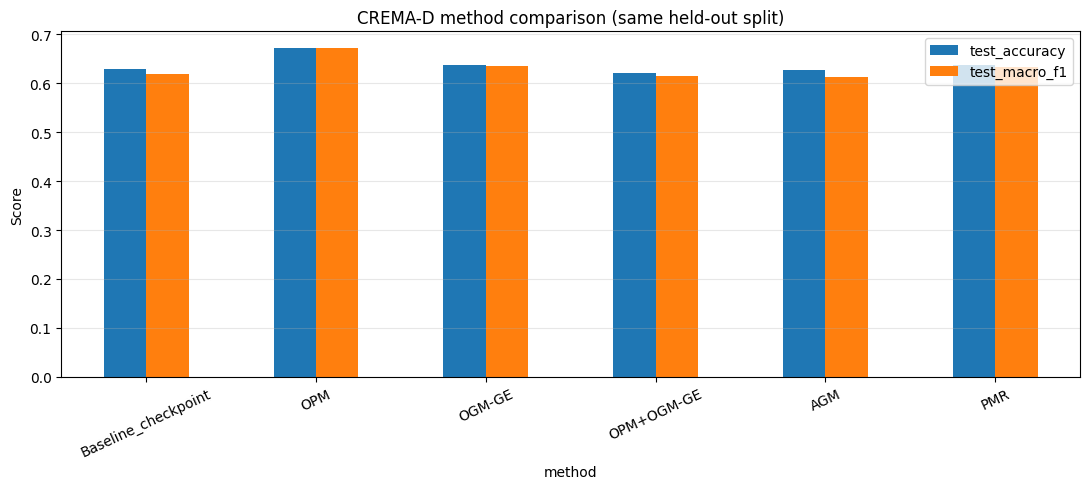

Saved results to /content/DL_project/modality_bias/results


In [18]:

comparison_path=RESULTS/"crema_d_method_comparison.csv"
comparison=pd.read_csv(comparison_path)
ax=comparison.set_index("method")[["test_accuracy","test_macro_f1"]].plot(kind="bar",figsize=(11,5),rot=25)
ax.set_ylabel("Score"); ax.set_title("CREMA-D method comparison (same held-out split)")
ax.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()

config={"dataset":"CREMA-D","baseline_checkpoint":str(BASE_CKPT),"cache":str(CACHE),
        "split_counts":meta["split"].value_counts().to_dict(),"seed":SEED,
        "epochs":EPOCHS,"methods":METHODS,"device":str(DEVICE),
        "note":"Method implementations are adaptations; verify paper-specific equations/hyperparameters before publication."}
with open(RESULTS/"crema_d_method_run_config.json","w") as f: json.dump(config,f,indent=2)
print("Saved results to",RESULTS)
